In [6]:

!pip install -q yfinance tensorflow scikit-learn
print("Libraries installed successfully!")


Libraries installed successfully!


In [7]:

import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Download Bitcoin daily data
df = yf.download(
    "BTC-USD",
    period="max",
    interval="1d",
    auto_adjust=False,
    progress=False
)

if df.empty:
    raise ValueError("Data download failed. Please run this cell again.")

# Handle different column formats
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df = df.reset_index()

# Select approximately 2000 daily records
df = df.tail(2000).copy()

# Keep date and closing price
df = df[["Date", "Close"]].dropna()
df = df.sort_values("Date").reset_index(drop=True)

print("Bitcoin dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())


Bitcoin dataset loaded successfully!
Dataset shape: (2000, 2)


Price,Date,Close
0,2021-05-02,56631.078125
1,2021-05-03,57200.292969
2,2021-05-04,53333.539062
3,2021-05-05,57424.007812
4,2021-05-06,56396.515625


In [8]:

print("Missing values before cleaning:")
print(df.isnull().sum())

df["Close"] = pd.to_numeric(df["Close"], errors="coerce")
df["Close"] = df["Close"].interpolate(limit_direction="both")
df = df.dropna(subset=["Close"])

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nTotal records:", len(df))


Missing values before cleaning:
Price
Date     0
Close    0
dtype: int64

Missing values after cleaning:
Price
Date     0
Close    0
dtype: int64

Total records: 2000


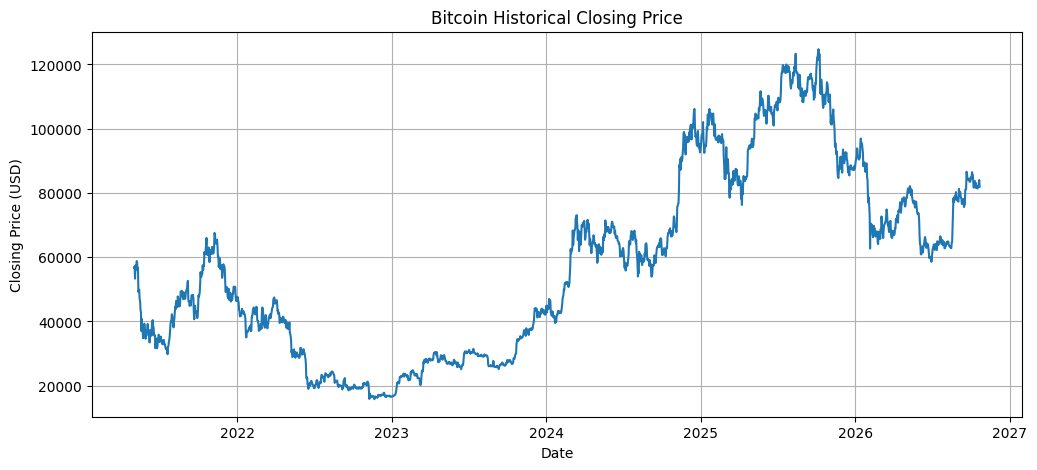

In [9]:

plt.figure(figsize=(12, 5))
plt.plot(df["Date"], df["Close"])
plt.title("Bitcoin Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)
plt.show()


In [10]:

from sklearn.preprocessing import MinMaxScaler

prices = df["Close"].to_numpy().reshape(-1, 1)

split_index = int(len(prices) * 0.80)

train_prices = prices[:split_index]
test_prices = prices[split_index:]

scaler = MinMaxScaler()

train_scaled = scaler.fit_transform(train_prices)
test_scaled = scaler.transform(test_prices)

print("Training records:", len(train_prices))
print("Testing records:", len(test_prices))
print("Normalization completed!")


Training records: 1600
Testing records: 400
Normalization completed!


In [11]:

window_size = 7

def create_sequences(data, window=7):
    X, y = [], []

    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])
        y.append(data[i, 0])

    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled)

test_context = np.concatenate(
    [train_scaled[-window_size:], test_scaled],
    axis=0
)

X_test, y_test = create_sequences(test_context)

X_train = X_train.reshape(-1, window_size, 1)
X_test = X_test.reshape(-1, window_size, 1)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Sliding windows created successfully!")


X_train: (1593, 7, 1)
X_test: (400, 7, 1)
Sliding windows created successfully!


In [12]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

tf.keras.utils.set_random_seed(42)

model = Sequential([
    tf.keras.Input(shape=(window_size, 1)),
    LSTM(50, return_sequences=True),
    Dropout(0.2),
    LSTM(25),
    Dense(1)
])

model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 7, 50)          │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 7, 50)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 25)             │         7,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 18,026 (70.41 KB)

 Trainable params: 18,026 (70.41 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

print("Model training completed!")


Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0196 - val_loss: 0.0090
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0093 - val_loss: 0.0093
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0087 - val_loss: 0.0062
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0059 - val_loss: 0.0032
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0040 - val_loss: 0.0021
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0031 - val_loss: 0.0010
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0028 - val_loss: 0.0011
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0029 - val_loss: 0.0012
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0032 - val_loss: 0.0014
Epoch 10/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0035 - val_loss: 0.0014
Epoch 11/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0038 - val_loss: 0.0015
Epoch 12/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.00

In [14]:

from sklearn.metrics import mean_absolute_error, mean_squared_error

pred_scaled = model.predict(X_test, verbose=0)

predicted = scaler.inverse_transform(pred_scaled).flatten()
actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))


Mean Absolute Error (MAE): 6042.92
Root Mean Squared Error (RMSE): 6703.5


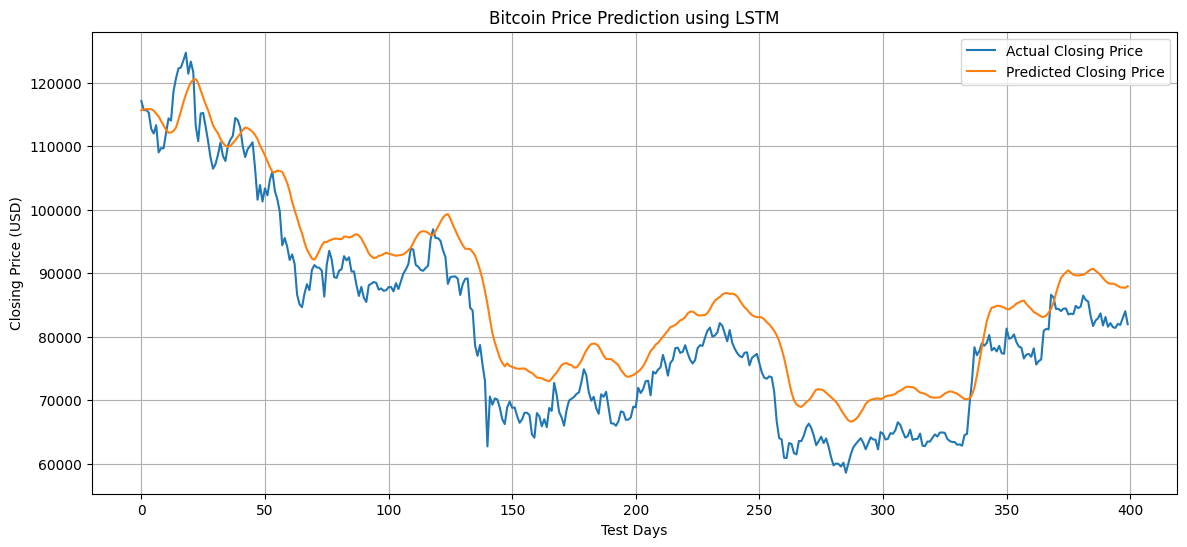

In [15]:

plt.figure(figsize=(14, 6))

plt.plot(actual, label="Actual Closing Price")
plt.plot(predicted, label="Predicted Closing Price")

plt.title("Bitcoin Price Prediction using LSTM")
plt.xlabel("Test Days")
plt.ylabel("Closing Price (USD)")
plt.legend()
plt.grid(True)
plt.show()


In [16]:

last_7 = prices[-7:]

last_7_scaled = scaler.transform(last_7)
next_input = last_7_scaled.reshape(1, 7, 1)

next_scaled = model.predict(next_input, verbose=0)
next_price = scaler.inverse_transform(next_scaled)[0, 0]

print("Last observed closing price:",
      round(float(prices[-1, 0]), 2))

print("Predicted next-day closing price:",
      round(float(next_price), 2), "USD")


Last observed closing price: 81968.4
Predicted next-day closing price: 88053.38 USD
